In [2]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from typing import TypedDict

In [3]:
class BlogState(TypedDict):
    title: str
    outline: str
    content: str

In [11]:
llm = ChatOpenAI(model="gpt-5")

In [13]:
def generate_outline(state: BlogState) -> BlogState:
    title = state["title"]
    prompt = f"Generate a 100 words outline for a blog on the topic - {title}"
    outline = llm.invoke(prompt)
    state["outline"] = outline.content

    return state

In [14]:
def generate_content(state: BlogState) -> BlogState:
    title = state["title"]
    outline = state["outline"]
    prompt = f'Write a 200 words detailed blog on the title - {title} using the follwing outline \n {outline}'
    content = llm.invoke(prompt)
    state["content"] = content.content

    return state

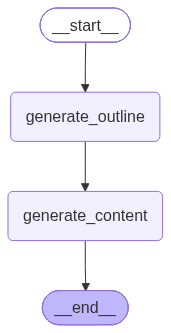

In [15]:
graph = StateGraph(BlogState)

graph.add_node("generate_outline", generate_outline)
graph.add_node("generate_content", generate_content)

graph.add_edge(START, "generate_outline")
graph.add_edge("generate_outline", "generate_content")
graph.add_edge("generate_content", END)

workflow = graph.compile()
workflow

In [16]:
init_state = {"title": "AI Contribution in India"}

final_state = workflow.invoke(init_state)

print(final_state)

{'title': 'AI Contribution in India', 'outline': '- Introduction: Why AI matters to India.\n- Snapshot of AI landscape and economic potential.\n- Government initiatives: Digital India, IndiaAI Mission, compute, policy.\n- Startup ecosystem and hubs: Bengaluru, Hyderabad, Delhi-NCR.\n- Academia and research: IITs, IISc, centers of excellence, industry links.\n- Sectoral impact: healthcare, agriculture, finance, manufacturing, education, governance, language tech.\n- Infrastructure: data, cloud, chips, and open-source contributions.\n- Skilling and inclusion: reskilling, vernacular AI, rural reach, women in STEM.\n- Ethics and regulation: privacy, bias, safety, accountability.\n- Case studies with measurable outcomes.\n- Challenges: talent gaps, infrastructure costs, datasets, MSME adoption.\n- Metrics: jobs, GDP, productivity gains tracking.\n- Roadmap: priorities, partnerships, funding.\n- Conclusion: call to collaborate.', 'content': 'AI matters to India because it can amplify scarce 